# Lab exercise 6: The Variational Auto-Encoder

# Name1: Ran Lu
# Name2: Xiaomeng Li
# Name3: Alizee Xia
The VAE that we will develop is based on the following generative story:
* $z\sim p_\theta(z)$
* $x \sim p_\theta(x|z;θ)$

where the latent representations z take value in $R^n$
. The prior ditribution $p(z)$ is a multivariate Gaussian where each coordinate is independent. We fix the mean and variance of each coordinate to 0 and 1, respectively. The conditional distribution $p(x|z;θ)$ is parameterized by a neural network: it is the decoder! The generated pixels x are independent Gaussians with a fixed variance.

Note: this kind of VAE will be quite bad at generating MNIST picture. Therefore, when you do you experiments, you should both generate picture and display the mean parameters of the output distributions. This is a well known problem of VAE, you can try to play with the network architecture and the parameters to improve generation.

Although the decoder is similar to the auto-encoder decoder, the encoder is different: it must return two tensors, the tensor of means and the tensor of variances. As the variance of a Gaussian distribution is constrained to be strictly positive, it is usual to instead return the log-variance (or log squared variance), which is unconstrained. If you exponentiate the log-variance, you get the variance which will be strictly positive as the exponential function only returns positive values.

Similarly to the auto-encoder, there are several hyperparameters you can try to tune. However, for the VAE I strongly advise you to:
* set the latent space dim to 2
* use [gradient clipping](https://pytorch-org.translate.goog/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html?_x_tr_sl=en&_x_tr_tl=fr&_x_tr_hl=fr&_x_tr_pto=sc) (bound the gradient) 


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from torch import optim
from torch.utils.data import DataLoader


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [2]:
class VAEEncoder(nn.Module):
    def __init__(self, dim_input, dim_latent):
        super().__init__()
        self.dim_input = dim_input
        self.dim_latent = dim_latent
        self.dim_inter = 256
        self.encoder =  nn.Sequential(
                            nn.Linear(self.dim_input, self.dim_inter),
                            nn.LeakyReLU(0, 2),
                            nn.Linear(self.dim_inter, self.dim_inter),
                            nn.LeakyReLU(0, 2)
                        ) 
        self.m_mu = nn.Linear(self.dim_inter, self.dim_latent)
        self.m_sigma = nn.Linear(self.dim_inter, self.dim_latent)
        

    def forward(self, inputs):
        inter = self.encoder(inputs)
        mu = self.m_mu(inter)
        log_sigma_squared = self.m_sigma(inter)
        # mu = mean
        # log_sigma_squared = log variance
        # The idea is that you use two different output projection:
        # one for the mean, one for the log_sigma_squared
        # but all other layers are shared
        return mu, log_sigma_squared
        
class VAEDecoder(nn.Module):
    def __init__(self, dim_latent, dim_output):
        super().__init__()
        self.dim_latent = dim_latent
        self.dim_output = dim_output
        self.decoder =  nn.Sequential(
                            nn.Linear(dim_latent, dim_output),
                            nn.LeakyReLU(0, 2),
                            nn.Linear(dim_output, dim_output),
                            nn.LeakyReLU(0, 2),
                            nn.Linear(dim_output, dim_output)
                        )

    def forward(self, z):
        img = torch.sigmoid(self.decoder(z))
        return img

To compute the training loss, you must compute two terms:
* A Monte-Carlo estimation of the reconstruction loss (you can start considering sampling only one z)
* The KL divergence between the distributions computed by the encoder and the prior

For the reconstruction loss, you can use the mean square error loss.

To sample values, you can use the reparameterization trick as follows: 
```
e = torch.normal(0, 1., mu.shape)
z = mu + e * torch.sqrt(torch.exp(log_sigma_squared))
```

For the formula of the $KL(q_\phi(z|x)|| p_\theta(z))$ you should have it from the exercise we did during the lecture. You can also check appendix of the [original paper](https://arxiv.org/pdf/1312.6114.pdf) 

You have in the following to implements:
* The training loop
* The two losses
* Choose which architecture for encoder and decoder

In [3]:
import torch.nn.functional as F

def KL(mu,log_sigma):
    '''
    We suppose that the prior is a centered gaussian
    '''
    kl = -0.5 * torch.sum(1 + log_sigma - mu**2 - torch.exp(log_sigma), dim=1)
    return torch.mean(kl)  # moyenne par échantillon


def reconstruction_loss(input_image, predicted_image):
    return nn.functional.binary_cross_entropy(predicted_image, input_image, reduction='sum')
    
def training_loop(dataset, encoder, decoder, n_sample_monte_carlo=1, max_epoch=50, learning_rate=1e-3, batch_size=128, max_grad_norm=5e-1):
    data_loader = DataLoader(list(dataset), batch_size=batch_size, shuffle=True, drop_last=True)
    optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=learning_rate)
    for epoch in range(max_epoch):
        losses = []
        for x in data_loader:
            x = x.to(device)
            optimizer.zero_grad()
            mu, log_sigma = encoder(x)
            # do sampling
            e = torch.randn(mu.shape, device=device)
            z =  e *torch.exp(log_sigma) + mu
            y = decoder(z) # distribution given

            loss = reconstruction_loss(x, y) + KL(mu, log_sigma)
            losses.append(loss.item()/128)
            
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(list(encoder.parameters()) + list(decoder.parameters()), max_grad_norm)
            optimizer.step()
        if epoch % 1 == 0:
            n = 5
            generated = decoder(torch.randn(n*n, 50))
            imgs = np.zeros((n*28, n*28))
            print(imgs.shape)
            for i in range(n*n):
                imgs[i//n  * 28: i//n * 28 + 28,i%n * 28 : i%n * 28 + 28] = generated[i].detach().numpy().reshape(28,28)
            
            plt.imshow(imgs, cmap='Greys')
            plt.show()
            print(f"The sum of losses for epoch {epoch} is {np.mean(losses)}")
                    



/Users/luran/Desktop/T4/3 - DL/dataset_loader.py:44: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  train_set, valid_set, test_set = pickle.load(f, encoding='latin-1') # compatibility issue between python 2.7 and 3.4


(140, 140)


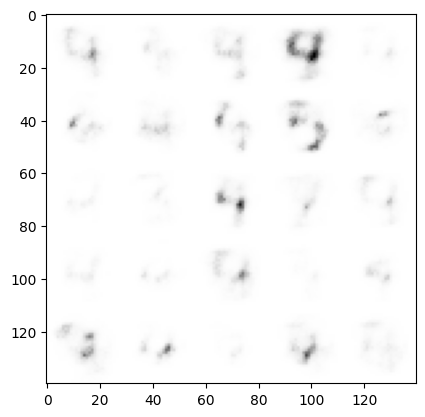

The sum of losses for epoch 0 is 160.14336694570687
(140, 140)


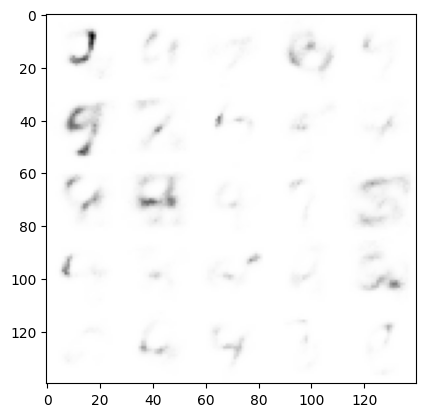

The sum of losses for epoch 1 is 103.78347649207483
(140, 140)


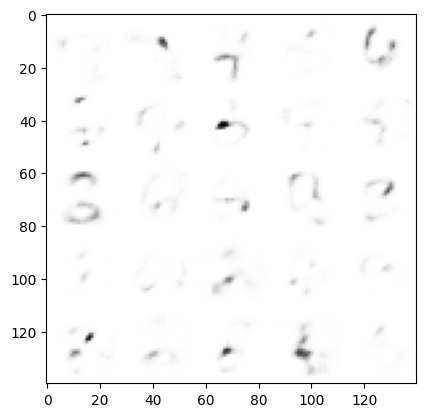

The sum of losses for epoch 2 is 88.22858100304236
(140, 140)


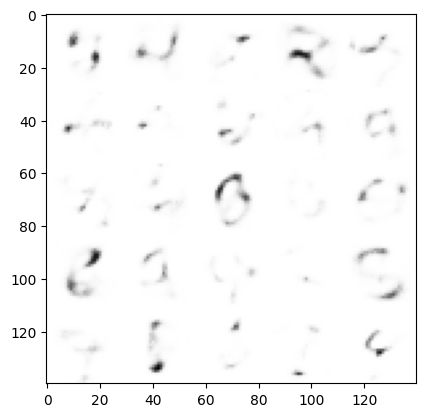

The sum of losses for epoch 3 is 79.5427602719038
(140, 140)


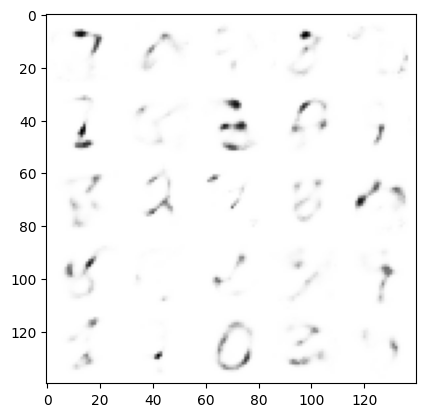

The sum of losses for epoch 4 is 74.77051618527143
(140, 140)


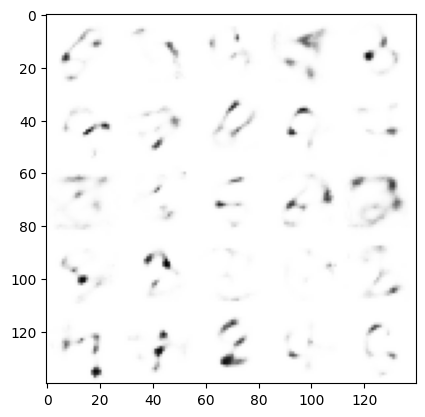

The sum of losses for epoch 5 is 71.89348304944161
(140, 140)


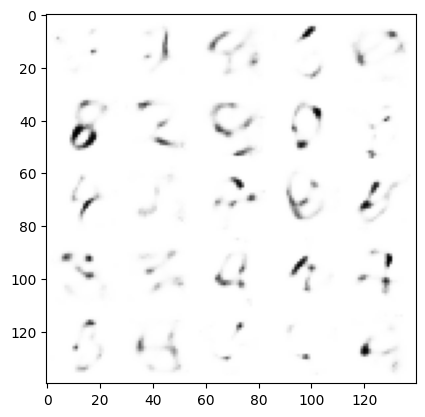

The sum of losses for epoch 6 is 69.52102127075196
(140, 140)


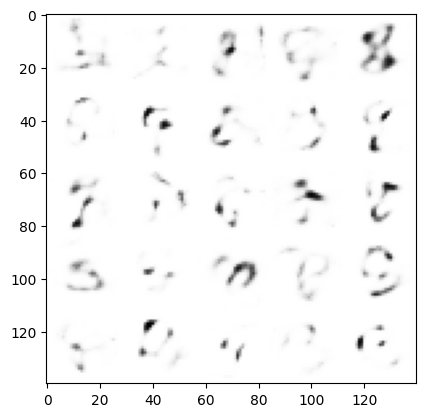

The sum of losses for epoch 7 is 67.79042911040477
(140, 140)


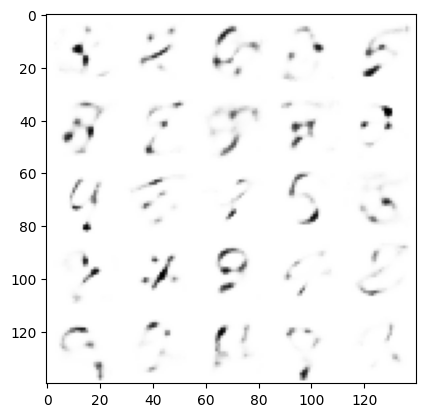

The sum of losses for epoch 8 is 66.55091786506848
(140, 140)


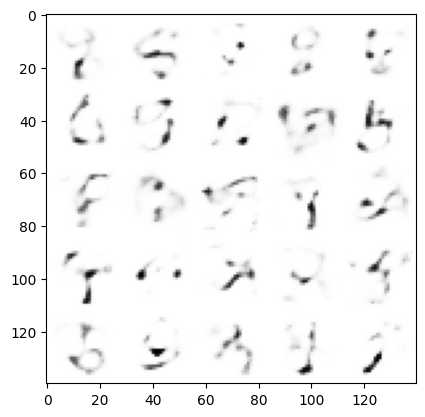

The sum of losses for epoch 9 is 65.61651496887207
(140, 140)


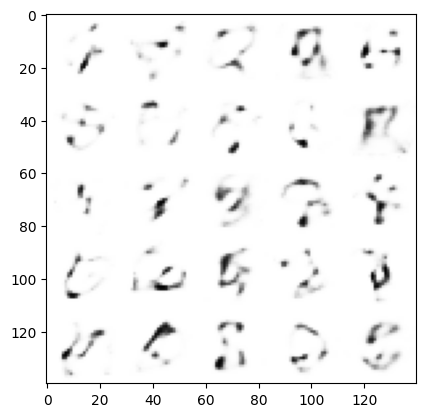

The sum of losses for epoch 10 is 64.80191641587477
(140, 140)


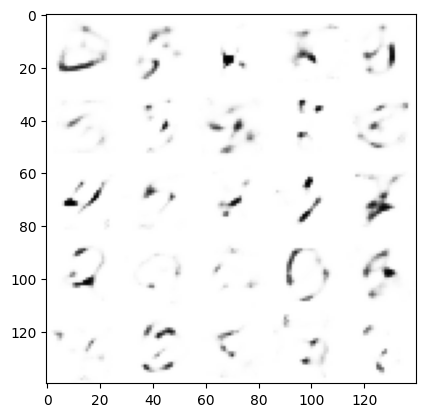

The sum of losses for epoch 11 is 64.05303562848997
(140, 140)


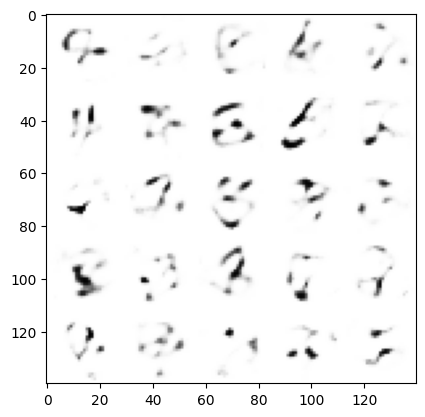

The sum of losses for epoch 12 is 63.43821957906087
(140, 140)


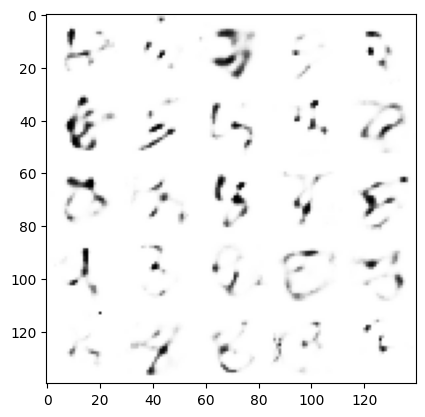

The sum of losses for epoch 13 is 62.898641850398135
(140, 140)


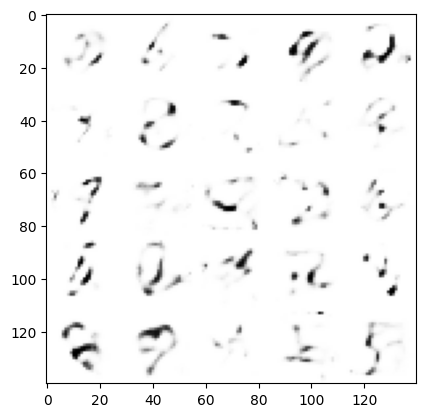

The sum of losses for epoch 14 is 62.40355973855043
(140, 140)


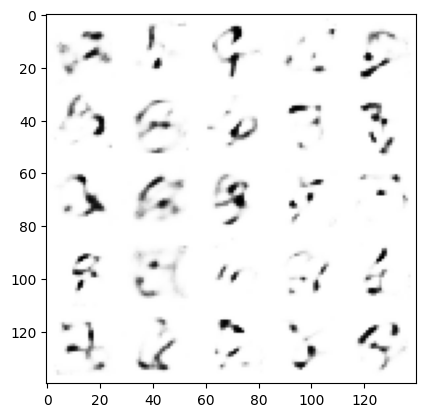

The sum of losses for epoch 15 is 61.95667839050293
(140, 140)


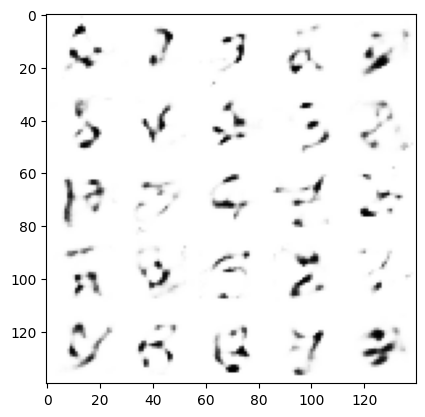

The sum of losses for epoch 16 is 61.537473443838266
(140, 140)


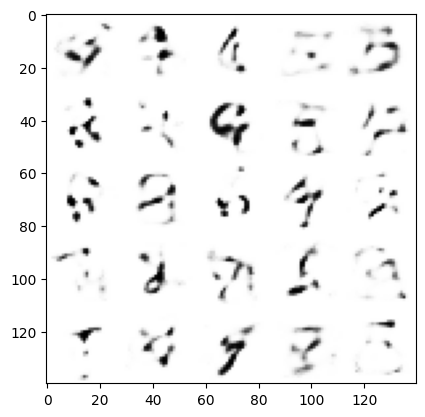

The sum of losses for epoch 17 is 61.13352174025316
(140, 140)


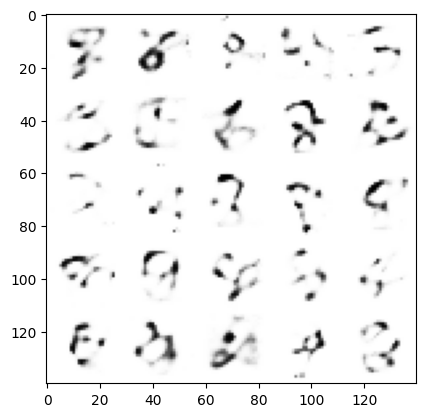

The sum of losses for epoch 18 is 60.8973258580917
(140, 140)


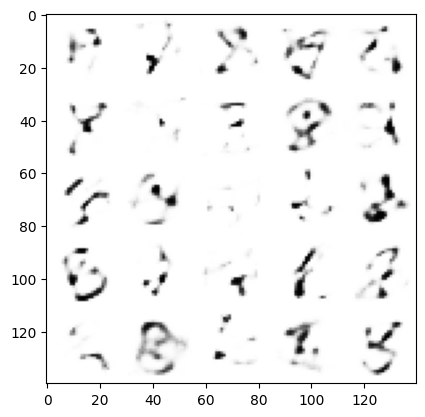

The sum of losses for epoch 19 is 60.59569454682179
(140, 140)


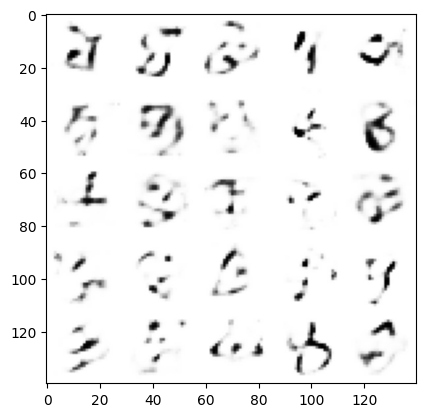

The sum of losses for epoch 20 is 60.353511536427035
(140, 140)


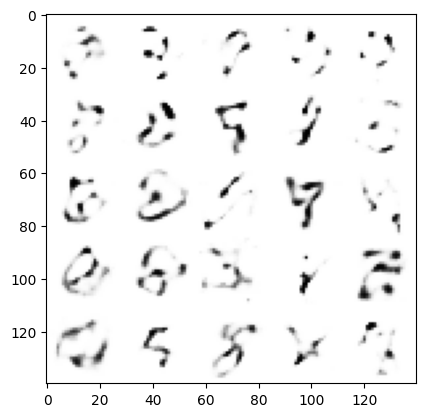

The sum of losses for epoch 21 is 60.1081613491743
(140, 140)


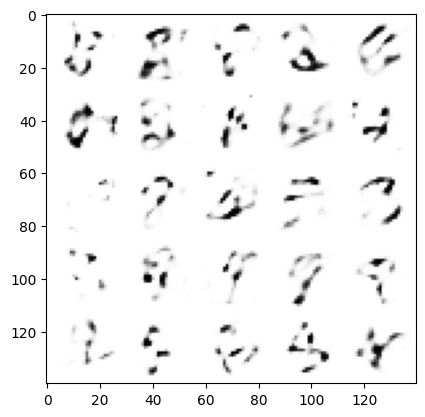

The sum of losses for epoch 22 is 59.853852384518355
(140, 140)


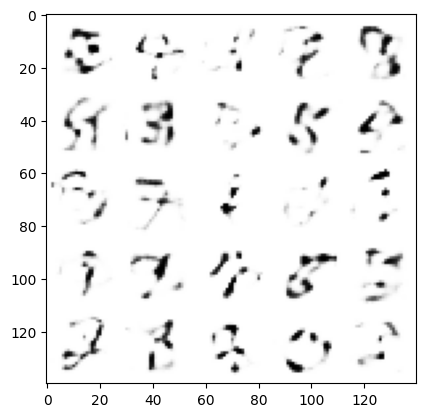

The sum of losses for epoch 23 is 59.68162029951046
(140, 140)


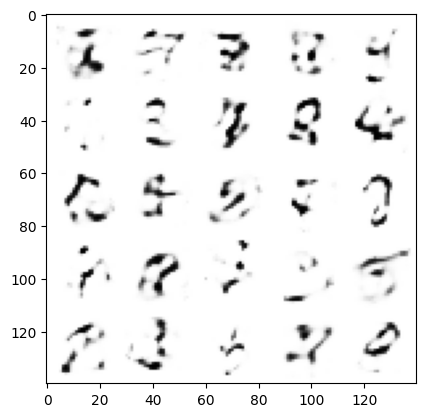

The sum of losses for epoch 24 is 59.50778026091747
(140, 140)


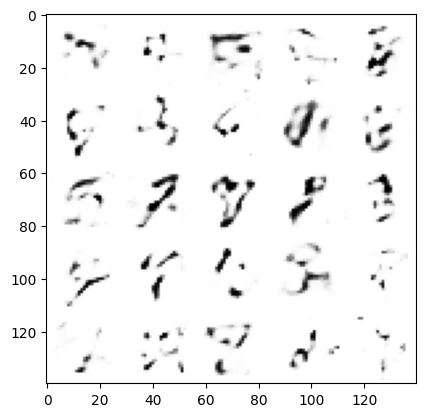

The sum of losses for epoch 25 is 59.3125374622834
(140, 140)


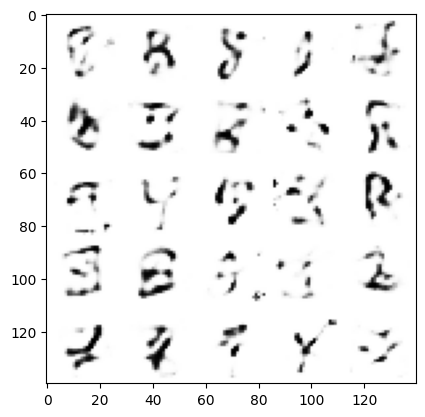

The sum of losses for epoch 26 is 59.162359325702376
(140, 140)


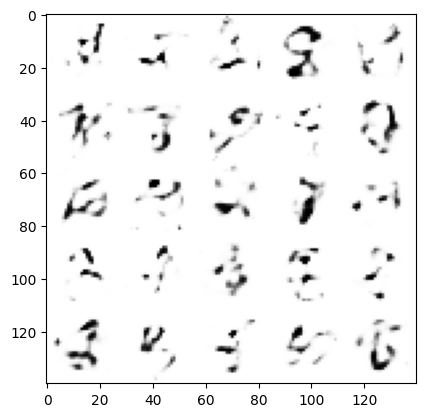

The sum of losses for epoch 27 is 58.98824668297401
(140, 140)


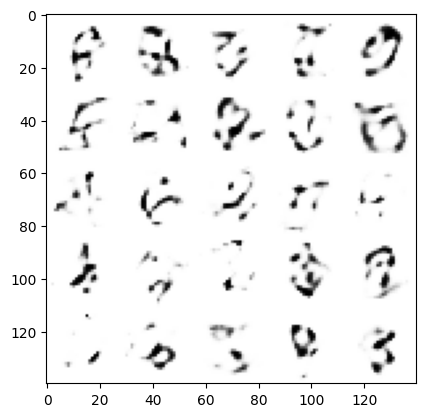

The sum of losses for epoch 28 is 58.817868208273865
(140, 140)


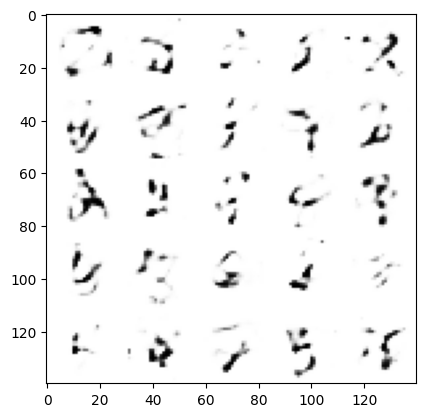

The sum of losses for epoch 29 is 58.68688672383626
(140, 140)


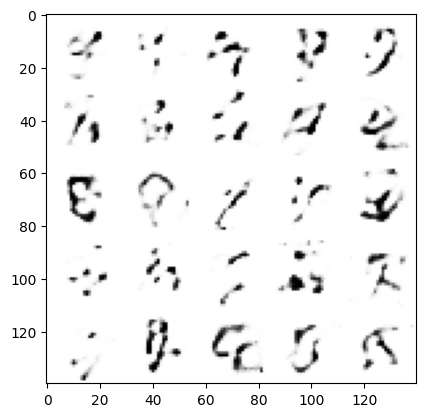

The sum of losses for epoch 30 is 58.5816533602201
(140, 140)


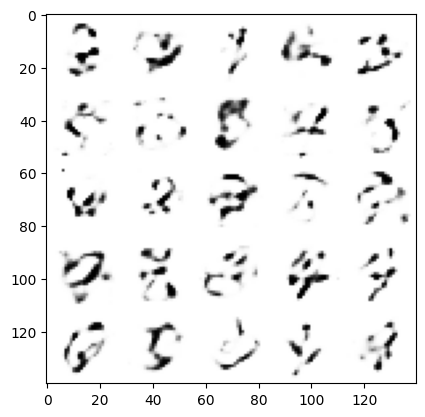

The sum of losses for epoch 31 is 58.46756968375964
(140, 140)


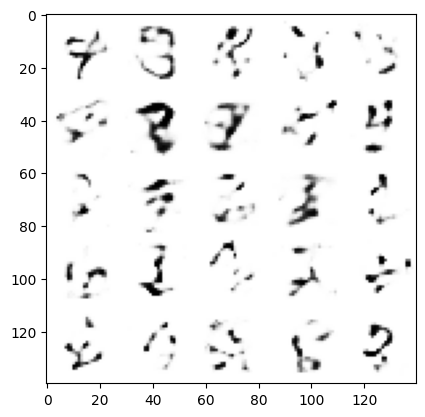

The sum of losses for epoch 32 is 58.334437306722
(140, 140)


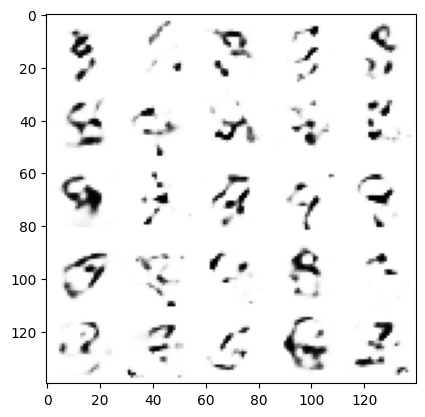

The sum of losses for epoch 33 is 58.244321118868314
(140, 140)


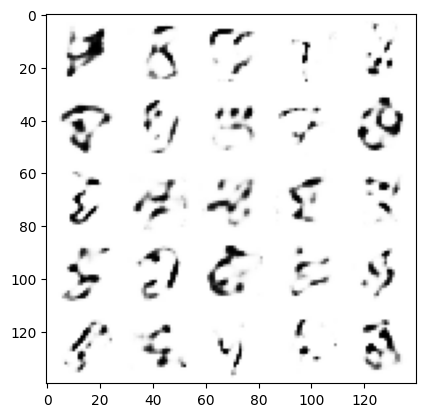

The sum of losses for epoch 34 is 58.12448450724284
(140, 140)


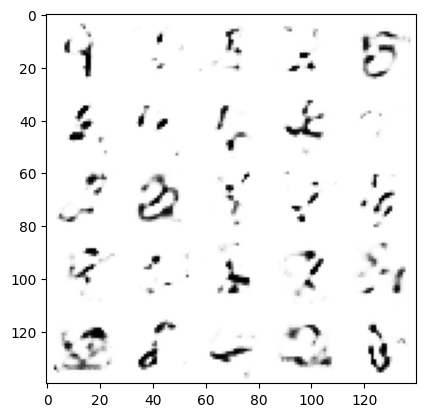

The sum of losses for epoch 35 is 58.01331682449732
(140, 140)


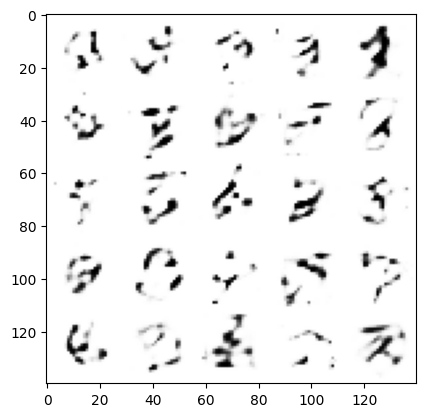

The sum of losses for epoch 36 is 57.93217413486578
(140, 140)


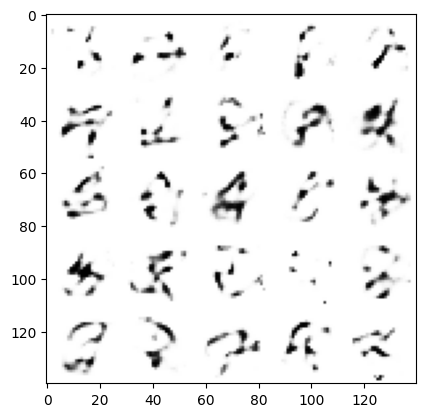

The sum of losses for epoch 37 is 57.83585741091997
(140, 140)


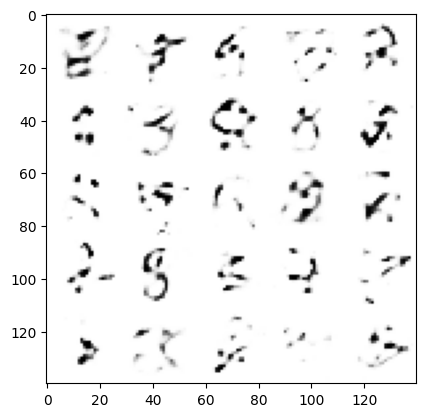

The sum of losses for epoch 38 is 57.729500755896936
(140, 140)


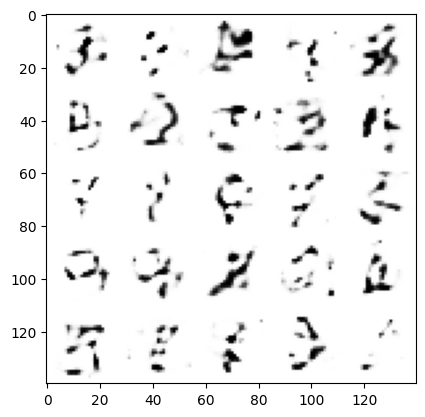

The sum of losses for epoch 39 is 57.64375269963191
(140, 140)


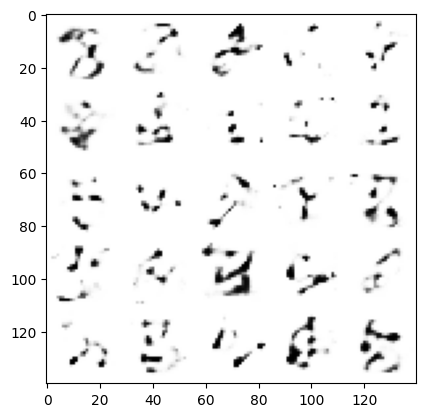

The sum of losses for epoch 40 is 57.561739936241736
(140, 140)


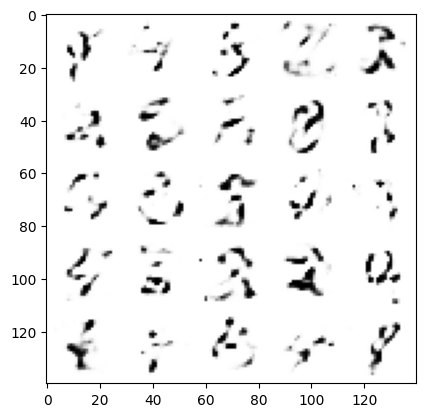

The sum of losses for epoch 41 is 57.483382826585036
(140, 140)


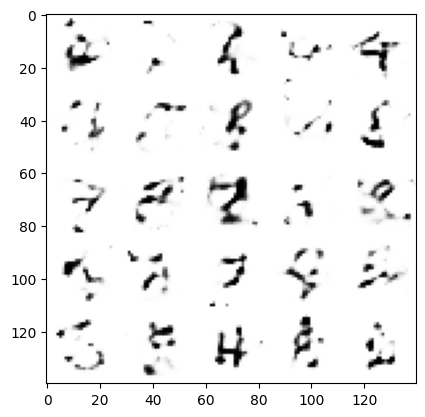

The sum of losses for epoch 42 is 57.38042028378218
(140, 140)


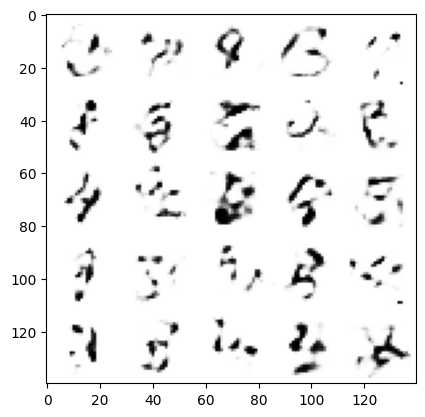

The sum of losses for epoch 43 is 57.35290918594752
(140, 140)


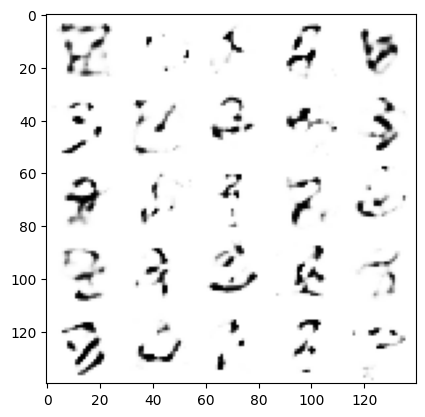

The sum of losses for epoch 44 is 57.250970361171625
(140, 140)


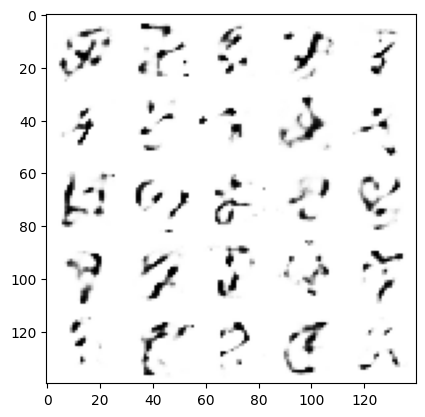

The sum of losses for epoch 45 is 57.18227035326836
(140, 140)


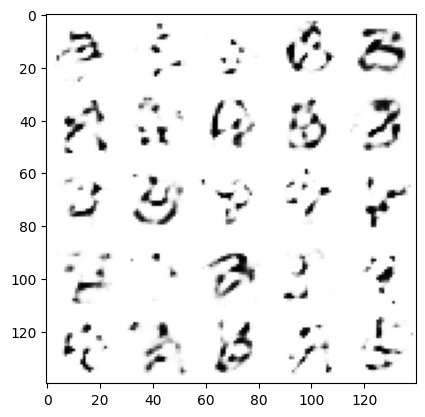

The sum of losses for epoch 46 is 57.10492122356708
(140, 140)


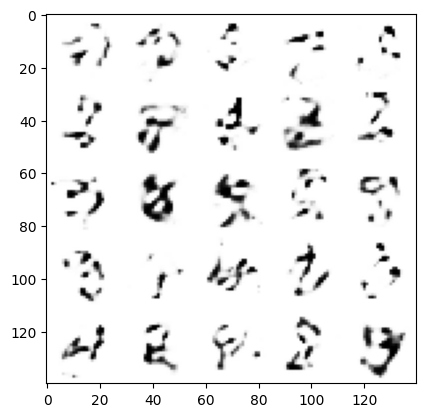

The sum of losses for epoch 47 is 57.03118739005847
(140, 140)


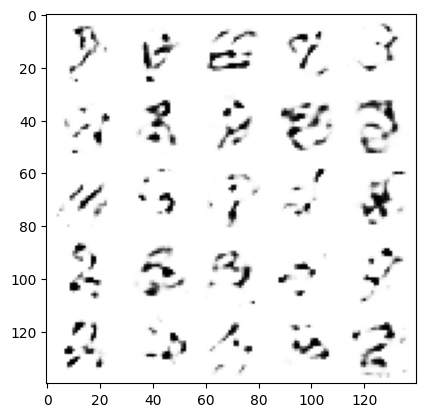

The sum of losses for epoch 48 is 56.97850852379432
(140, 140)


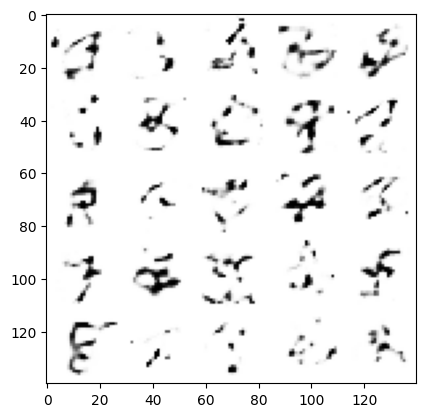

The sum of losses for epoch 49 is 56.91981009458884


In [4]:
import os
import dataset_loader # file given in lab 3
# Download mnist dataset 
if("mnist.pkl.gz" not in os.listdir(".")):
    # this link doesn't work any more,
    # seach on google for the file "mnist.pkl.gz"
    # and download it
    !wget https://github.com/mnielsen/neural-networks-and-deep-learning/raw/master/data/mnist.pkl.gz
    


# if you have it somewhere else, you can comment the lines above
# and overwrite the path below
mnist_path = "./mnist.pkl.gz"


train_data, dev_data, test_data = dataset_loader.load_mnist(mnist_path)

dataset = train_data[0] # we are not interrested having labels

encoder = VAEEncoder(dataset[0].shape[0], 50).to(device)
decoder = VAEDecoder(50, dataset[0].shape[0]).to(device)

training_loop(dataset, encoder, decoder)

## Generating new images

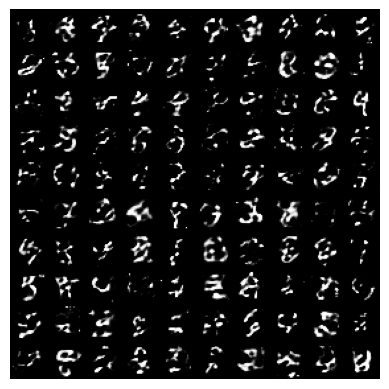

In [7]:
n = 10
latent_dim = 50
mu = torch.zeros(n * n, latent_dim)
z = torch.normal(0, 1., mu.shape) # sampling

generated = decoder(z)
imgs = np.zeros((n*28, n*28))

plt.figure()
for i in range(n*n):
    imgs[i//n  * 28: i//n * 28 + 28,i%n * 28 : i%n * 28 + 28] = 1 - generated[i].detach().numpy().reshape(28,28)
plt.axis('off')
plt.imshow(imgs, cmap='Greys')

## Latent space visualization

It is quite useful to visualize the latent space the variational auto-encoder. You can visualize it either for the training data or the dev data. Note that if you want to visualize a latent space when its dimension is greater than two (useful for the first part!), you could project it in 2 dimensions using PCA (its already implemented in scikit-learn!) 

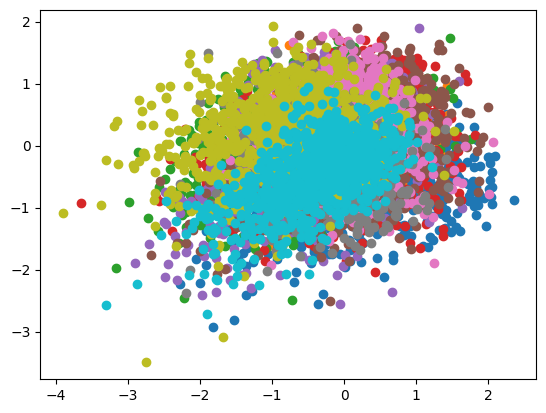

In [8]:
import matplotlib.cm as cm

labels = np.array(dev_data[1])
images = np.array(dev_data[0])
dl = DataLoader(list(zip(images, labels)), batch_size=128, shuffle=True, drop_last=True)
az = []
ay = []
with torch.no_grad():
    for x, y in dl:
        x = x.to(device)
        y = y.to(device)
        mu, log_sigma = encoder(x)

        z = torch.randn(mu.shape) * torch.exp(0.5 * log_sigma) + mu
        az += z.tolist()
        ay += y.tolist()
az = np.array(az)
ay = np.array(ay)

colors = cm.rainbow(np.linspace(0, 1, 10))
for i in range(10):
    plt.scatter(az[ay == i][:, 0], az[ay == i][:, 1])